# 06 — Giải Đấu Round-Robin & Phân Tích Hành Vi / Phong Cách Chơi (RQ4)

Notebook này tổng hợp kết quả giải đấu trong `results/round_robin/matches.jsonl` & `games.pgn`, vẽ **ma trận đối đầu (Heatmap tỷ lệ điểm $S$)** kèm khoảng tin cậy **Wilson 95%**, và tính các chỉ số định lượng phong cách thi đấu (**RQ4**: độ dài ván trung bình, tỷ lệ chiếu hết, tỷ lệ hòa, tỷ lệ nhập thành sớm).

In [1]:
from collections import defaultdict
import json
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.arena.metrics import compute_style_metrics, wilson_confidence_interval

matches_path = PROJECT_ROOT / "results" / "round_robin" / "matches.jsonl"
records = [json.loads(line) for line in matches_path.read_text(encoding="utf-8").splitlines() if line.strip()]
print(f"Tổng số ván đấu ghi nhận trong matches.jsonl: {len(records)}")

Tổng số ván đấu ghi nhận trong matches.jsonl: 80


## 1. Ma Trận Đối Đầu & Bảng Xếp Hạng (Wilson 95% CI)

,Tác tử,Số ván,W/D/L,Score (%),Wilson 95% CI
0,Level3_AlphaBeta,40,37/3/0,96.2,"[85.3%, 99.1%]"
1,Level4_MCTS_UCT,20,18/2/0,95.0,"[76.4%, 99.1%]"
2,Level2_Heuristic,40,20/3/17,53.8,"[38.7%, 68.2%]"
3,Level1_Random,60,0/2/58,1.7,"[0.3%, 8.9%]"


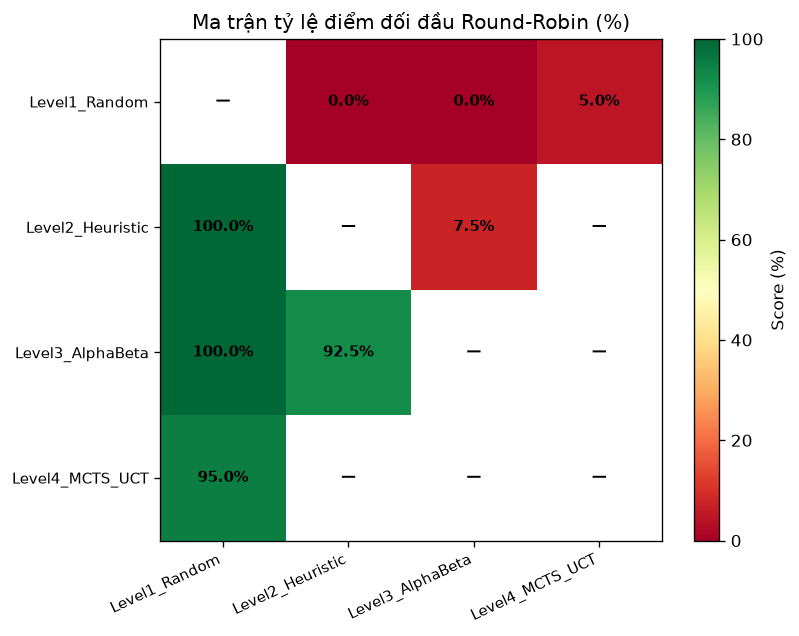

In [2]:
agents = sorted({r["white"] for r in records} | {r["black"] for r in records})
pair_wdl = defaultdict(lambda: [0, 0, 0])  # [W, D, L] cho agent hàng gặp agent cột
total_wdl = defaultdict(lambda: [0, 0, 0])

for r in records:
    w, b, res = r["white"], r["black"], r["result"]
    if res == "1-0":
        pair_wdl[(w, b)][0] += 1; pair_wdl[(b, w)][2] += 1
        total_wdl[w][0] += 1; total_wdl[b][2] += 1
    elif res == "0-1":
        pair_wdl[(w, b)][2] += 1; pair_wdl[(b, w)][0] += 1
        total_wdl[w][2] += 1; total_wdl[b][0] += 1
    else:
        pair_wdl[(w, b)][1] += 1; pair_wdl[(b, w)][1] += 1
        total_wdl[w][1] += 1; total_wdl[b][1] += 1

rank_rows = []
for ag in agents:
    w, d, l = total_wdl[ag]
    n = w + d + l
    s = (w + 0.5 * d) / max(1, n)
    lo, hi = wilson_confidence_interval(s, n) if n > 0 else (0.0, 1.0)
    rank_rows.append({"Tác tử": ag, "Số ván": n, "W/D/L": f"{w}/{d}/{l}", "Score (%)": round(s * 100, 1), "Wilson 95% CI": f"[{lo*100:.1f}%, {hi*100:.1f}%]"})
df_rank = pd.DataFrame(rank_rows).sort_values("Score (%)", ascending=False).reset_index(drop=True)
display(df_rank)

mat = np.full((len(agents), len(agents)), np.nan)
for i, a in enumerate(agents):
    for j, b in enumerate(agents):
        if i == j:
            continue
        w, d, l = pair_wdl[(a, b)]
        n = w + d + l
        if n > 0:
            mat[i, j] = (w + 0.5 * d) * 100.0 / n

fig, ax = plt.subplots(figsize=(6.8, 5.4), dpi=120)
im = ax.imshow(mat, cmap="RdYlGn", vmin=0, vmax=100)
ax.set_xticks(range(len(agents))); ax.set_xticklabels(agents, rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(len(agents))); ax.set_yticklabels(agents, fontsize=9)
for i in range(len(agents)):
    for j in range(len(agents)):
        txt = "—" if np.isnan(mat[i, j]) else f"{mat[i, j]:.1f}%"
        ax.text(j, i, txt, ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_title("Ma trận tỷ lệ điểm đối đầu Round-Robin (%)")
fig.colorbar(im, ax=ax, label="Score (%)")
plt.tight_layout()
plt.show()

## 2. Phân Tích Định Lượng Phong Cách Thi Đấu (RQ4) & Trích Xuất Ván Mẫu PGN

,Tác tử,Số ván,Độ dài TB (plies),Tỷ lệ chiếu hết (%),Tỷ lệ hòa (%),Tỷ lệ nhập thành sớm (%)
0,Level1_Random,60,59.3,96.7,3.3,31.7
1,Level2_Heuristic,40,50.7,92.5,7.5,77.5
2,Level3_AlphaBeta,40,45.5,92.5,7.5,52.5
3,Level4_MCTS_UCT,20,114.2,90.0,10.0,5.0


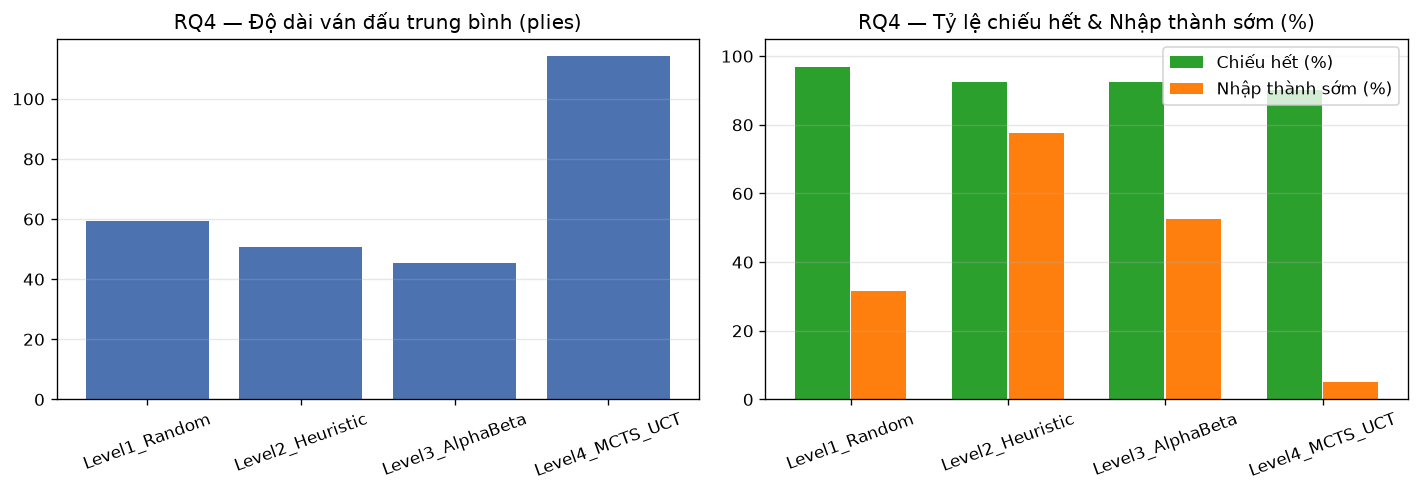

=== TRÍCH ĐOẠN VÁN ĐẤU MẪU (games.pgn) ===

[Event "101_TTNTNC Arena (workload_control)"]
[Site "OPEN.001"]
[Date "????.??.??"]
[Round "?"]
[White "Level1_Random"]
[Black "Level2_Heuristic"]
[Result "0-1"]
[FEN "rnbqkb1r/ppp1pp1p/3p2p1/3nP3/3P4/5N2/PPP2PPP/RNBQKB1R w KQkq - 0 1"]
[SetUp "1"]

1. Bc4 dxe5 2. b4 Nc6 3. Bxd5 Qxd5 4. dxe5 Qxd1+ 5. Kxd1 Nxb4 6. Bd2 e6 7. c4
Bc5 8. h3 O-O 9. Rh2 Bd7 10. Bxb4 Bxb4 11. Nc3 Bxc3 12. g3 Bxa1 13. Ke2 Bc3 14.
Ne1 Bxe5 15. f4 Bd4 16. Kf3 e5 17. a3 exf4 18. Kxf4 Rfe8 19. Ra2 Rxe1 20. Rg2
Bxh3 21. Rf2 Bxf2 22. Kg5 Bxg3 23. Kh6 Bf4# 0-1


In [3]:
style_rows = []
for ag in agents:
    ag_recs = [r for r in records if r["white"] == ag or r["black"] == ag]
    st = compute_style_metrics(ag_recs)
    style_rows.append({
        "Tác tử": ag,
        "Số ván": len(ag_recs),
        "Độ dài TB (plies)": round(st["avg_game_length_plies"], 1),
        "Tỷ lệ chiếu hết (%)": round(st["checkmate_rate"] * 100.0, 1),
        "Tỷ lệ hòa (%)": round(st["draw_rate"] * 100.0, 1),
        "Tỷ lệ nhập thành sớm (%)": round(st["castling_rate"] * 100.0, 1),
    })
df_style = pd.DataFrame(style_rows)
display(df_style)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), dpi=120)
ax1.bar(df_style["Tác tử"], df_style["Độ dài TB (plies)"], color="#4c72b0")
ax1.set_title("RQ4 — Độ dài ván đấu trung bình (plies)"); ax1.tick_params(axis="x", rotation=20); ax1.grid(True, axis="y", alpha=0.3)

x = np.arange(len(df_style))
ax2.bar(x - 0.18, df_style["Tỷ lệ chiếu hết (%)"], width=0.35, label="Chiếu hết (%)", color="#2ca02c")
ax2.bar(x + 0.18, df_style["Tỷ lệ nhập thành sớm (%)"], width=0.35, label="Nhập thành sớm (%)", color="#ff7f0e")
ax2.set_xticks(x); ax2.set_xticklabels(df_style["Tác tử"], rotation=20)
ax2.set_title("RQ4 — Tỷ lệ chiếu hết & Nhập thành sớm (%)"); ax2.set_ylim(0, 105); ax2.grid(True, axis="y", alpha=0.3); ax2.legend()
plt.tight_layout()
plt.show()

# In 1 ván mẫu tiêu biểu từ games.pgn
pgn_path = PROJECT_ROOT / "results" / "round_robin" / "games.pgn"
if pgn_path.exists():
    first_game = pgn_path.read_text(encoding="utf-8").split("\n\n[Event ")[0]
    print("=== TRÍCH ĐOẠN VÁN ĐẤU MẪU (games.pgn) ===\n")
    print(first_game[:900])